In [8]:
# Cell 1 — Imports, paths, and parameters
#
# Purpose:
# Compare candidate active-domain thresholds using the existing
# P28 threshold-selection procedure.

from pathlib import Path
from time import perf_counter
import json

import matplotlib.pyplot as plt
import numba as nb
import numpy as np
import pandas as pd

from scipy import ndimage as ndi
from skimage.morphology import skeletonize


# --------------------------------------------------
# 1. Project paths
# --------------------------------------------------

def find_project_root(start=None):
    start_path = Path.cwd() if start is None else Path(start)
    start_path = start_path.resolve()

    for directory in (start_path, *start_path.parents):
        if (
            (directory / "README.md").is_file()
            and (directory / "notebooks").is_dir()
            and (directory / "data").is_dir()
        ):
            return directory

    raise FileNotFoundError(
        "Run this notebook from within the repository containing "
        "README.md, notebooks/, and data/."
    )


PROJECT_ROOT = find_project_root()
DATA_ROOT = PROJECT_ROOT


def project_relative(path):
    return Path(path).relative_to(PROJECT_ROOT).as_posix()

SAMPLE_NAME = "p28_330_HET_009"

INPUT_DIR = (
    DATA_ROOT
    / "results"
    / SAMPLE_NAME
    / "05_soma_target"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / SAMPLE_NAME
    / "06_active_threshold_selection"
)


# --------------------------------------------------
# 2. Candidate active-domain thresholds
# --------------------------------------------------

ACTIVE_THRESHOLDS = np.array(
    [0.08, 0.09, 0.10, 0.11, 0.12,0.13,0.14,0.15],
    dtype=np.float64,
)

SIGNAL_POWER = 5.0
NUMERICAL_EPSILON = 1e-12
TARGET_DILATION_ITERATIONS = 2


# --------------------------------------------------
# 3. Original Step06 solver settings
# --------------------------------------------------

# Allowed steps satisfy:
# neighbor_distance_squared <= current_distance_squared + 3.
INNER_SQUARED_TOLERANCE = 3.0

MAXIMUM_ITERATIONS = 3000
CONVERGENCE_TOLERANCE = 1e-7
CONVERGENCE_CHECK_INTERVAL = 10


# --------------------------------------------------
# 4. Threshold-comparison settings
# --------------------------------------------------

# Convert each hitting-probability MIP into a comparison mask.
HITTING_DISPLAY_CUTOFF = 0.01

# Existing P28 reference value recorded in the original Step06.
# This is not the selected active-domain threshold.
REFERENCE_SIGNAL_THRESHOLD = 0.251336120624123

# The original metric uses the result at this threshold
# to define the reference territory.
REFERENCE_ACTIVE_THRESHOLD = 0.12

REFERENCE_TERRITORY_DILATION = 3
REFERENCE_SUPPORT_DILATION = 4


# --------------------------------------------------
# 5. Check the exported inputs
# --------------------------------------------------

INPUT_FILES = {
    "metadata": INPUT_DIR / "roi_metadata.csv",
    "signal": INPUT_DIR / "mg_probability_roi_yxz_float32.bin",
    "target": INPUT_DIR / "soma_target_roi_yxz_uint8.bin",
    "raw_mip": INPUT_DIR / "raw_mip_roi_yx_float32.bin",
}

missing_files = [
    project_relative(path)
    for path in INPUT_FILES.values()
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Missing input files:\n" + "\n".join(missing_files)
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Sample: {SAMPLE_NAME}")
print(f"Input directory: {project_relative(INPUT_DIR)}")
print(f"Output directory: {project_relative(OUTPUT_DIR)}")
print(f"Candidate thresholds: {ACTIVE_THRESHOLDS}")
print("All required input files were found.")

Sample: p28_330_HET_009
Input directory: results/p28_330_HET_009/05_soma_target
Output directory: results/p28_330_HET_009/06_active_threshold_selection
Candidate thresholds: [0.08 0.09 0.1  0.11 0.12 0.13 0.14 0.15]
All required input files were found.


In [9]:
# Cell 2 — Load the ROI data exported by Step05
#
# R storage: Y, X, Z in column-major order.
# Python solver: Z, Y, X.

# --------------------------------------------------
# 1. Read ROI metadata
# --------------------------------------------------

metadata_table = pd.read_csv(INPUT_FILES["metadata"])

if len(metadata_table) != 1:
    raise ValueError("Expected one row of ROI metadata.")

metadata = metadata_table.iloc[0]

shape_yxz = (
    int(metadata["dim_y"]),
    int(metadata["dim_x"]),
    int(metadata["dim_z"]),
)

shape_zyx = (
    shape_yxz[2],
    shape_yxz[0],
    shape_yxz[1],
)


# --------------------------------------------------
# 2. Read the normalized 3D signal
# --------------------------------------------------

signal_yxz = np.fromfile(
    INPUT_FILES["signal"],
    dtype="<f4",
).reshape(
    shape_yxz,
    order="F",
)


# --------------------------------------------------
# 3. Read the fixed 3D soma target
# --------------------------------------------------

target_yxz = np.fromfile(
    INPUT_FILES["target"],
    dtype=np.uint8,
).reshape(
    shape_yxz,
    order="F",
).astype(bool)


# --------------------------------------------------
# 4. Read the raw-image MIP
# --------------------------------------------------

raw_mip_yx = np.fromfile(
    INPUT_FILES["raw_mip"],
    dtype="<f4",
).reshape(
    shape_yxz[:2],
    order="F",
)


# --------------------------------------------------
# 5. Move Z to the first axis
# --------------------------------------------------

signal_zyx = np.moveaxis(signal_yxz, 2, 0)
target_zyx = np.moveaxis(target_yxz, 2, 0)

assert signal_zyx.shape == shape_zyx
assert target_zyx.shape == shape_zyx
assert raw_mip_yx.shape == shape_yxz[:2]

if not target_zyx.any():
    raise ValueError("The soma target is empty.")

if not np.isfinite(signal_zyx).all():
    raise ValueError("The input signal contains non-finite values.")

signal_min = float(signal_zyx.min())
signal_max = float(signal_zyx.max())

if not (0.0 <= signal_min <= signal_max <= 1.0):
    raise ValueError("Expected normalized signal values within [0, 1].")


# --------------------------------------------------
# 6. Report dimensions and target bounds
# --------------------------------------------------

target_coordinates_zyx = np.argwhere(target_zyx)

target_bounds = pd.DataFrame({
    "axis": ["Z", "Y", "X"],
    "minimum": target_coordinates_zyx.min(axis=0),
    "maximum": target_coordinates_zyx.max(axis=0),
})

print(f"R array shape (Y, X, Z):      {shape_yxz}")
print(f"Signal shape (Z, Y, X):       {signal_zyx.shape}")
print(f"Soma-target shape (Z, Y, X):  {target_zyx.shape}")
print(f"Raw-MIP shape (Y, X):         {raw_mip_yx.shape}")
print(f"Signal range:                {signal_min:.6g} to {signal_max:.6g}")
print(f"Soma-target voxels:          {int(target_zyx.sum()):,}")

print("\nSoma-target bounds, zero-based:")
print(target_bounds.to_string(index=False))

R array shape (Y, X, Z):      (241, 241, 161)
Signal shape (Z, Y, X):       (161, 241, 241)
Soma-target shape (Z, Y, X):  (161, 241, 241)
Raw-MIP shape (Y, X):         (241, 241)
Signal range:                0 to 1
Soma-target voxels:          2,829

Soma-target bounds, zero-based:
axis  minimum  maximum
   Z       28       46
   Y      105      138
   X      104      138


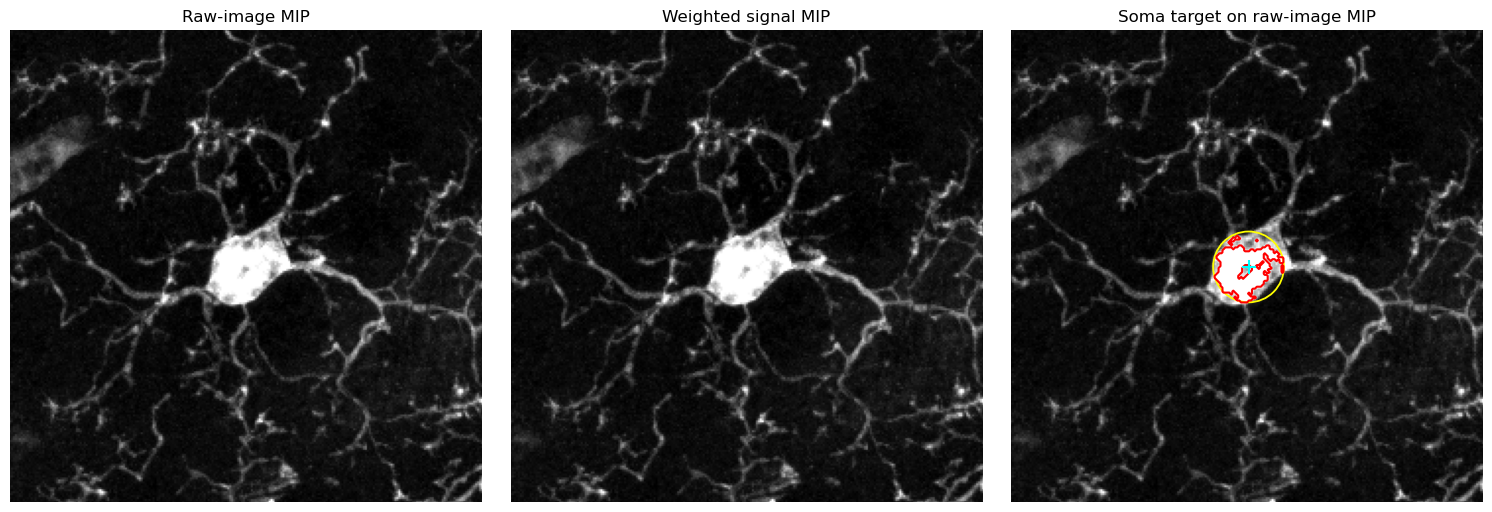

In [10]:
# Cell 3 — Visual QC after R-to-Python conversion

%matplotlib inline


# --------------------------------------------------
# 1. Create the signal and target projections
# --------------------------------------------------

signal_mip_yx = signal_zyx.max(axis=0)
target_mip_yx = target_zyx.any(axis=0)

soma_center_x_local = float(metadata["soma_center_x_local"])
soma_center_y_local = float(metadata["soma_center_y_local"])
soma_radius_xy = float(metadata["soma_radius_xy"])


# --------------------------------------------------
# 2. Adjust contrast for display
# --------------------------------------------------

def normalize_for_display(image):
    finite_values = image[np.isfinite(image)]

    if finite_values.size == 0:
        raise ValueError("The image contains no finite values.")

    lower_value, upper_value = np.percentile(
        finite_values,
        [1.0, 99.8],
    )

    return np.clip(
        (image - lower_value)
        / max(upper_value - lower_value, 1e-8),
        0.0,
        1.0,
    )


# These display arrays are separate from the input signal.
raw_mip_display_yx = normalize_for_display(raw_mip_yx)
signal_mip_display_yx = normalize_for_display(signal_mip_yx)


# --------------------------------------------------
# 3. Display the three QC panels
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5),
    constrained_layout=True,
)

images = [
    raw_mip_display_yx,
    signal_mip_display_yx,
    raw_mip_display_yx,
]

titles = [
    "Raw-image MIP",
    "Weighted signal MIP",
    "Soma target on raw-image MIP",
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(
        image,
        cmap="gray",
        origin="upper",
        vmin=0,
        vmax=1,
    )
    ax.set_title(title)
    ax.set_xlim(0, raw_mip_yx.shape[1] - 1)
    ax.set_ylim(raw_mip_yx.shape[0] - 1, 0)
    ax.set_aspect("equal")
    ax.set_axis_off()


# Red: projected 3D soma target.
axes[2].contour(
    target_mip_yx,
    levels=[0.5],
    colors=["red"],
    linewidths=1.5,
)

# Yellow: XY footprint of the soma cylinder.
axes[2].add_patch(
    plt.Circle(
        (soma_center_x_local, soma_center_y_local),
        soma_radius_xy,
        fill=False,
        edgecolor="yellow",
        linewidth=1.3,
    )
)

# Cyan: soma center.
axes[2].plot(
    soma_center_x_local,
    soma_center_y_local,
    marker="+",
    color="cyan",
    markersize=10,
    markeredgewidth=1.5,
)

plt.show()

In [11]:
# Cell 4 — Build the active domain for each candidate threshold

# --------------------------------------------------
# 1. Prepare transition weights
# --------------------------------------------------

signal_weights_zyx = (
    np.power(
        np.clip(signal_zyx, 0.0, 1.0),
        SIGNAL_POWER,
    ).astype(np.float64)
    + NUMERICAL_EPSILON
)


# --------------------------------------------------
# 2. Define the active-domain construction
# --------------------------------------------------

def build_target_connected_active(
    signal_zyx,
    target_zyx,
    active_threshold,
):
    thresholded_zyx = signal_zyx >= active_threshold

    # Face-, edge-, and corner-touching voxels are connected.
    connectivity_3d = np.ones((3, 3, 3), dtype=bool)

    component_labels, number_of_components = ndi.label(
        thresholded_zyx,
        structure=connectivity_3d,
    )

    # Use the expanded target only to identify nearby components.
    target_neighborhood = ndi.binary_dilation(
        target_zyx,
        structure=connectivity_3d,
        iterations=TARGET_DILATION_ITERATIONS,
    )

    touching_component_ids = np.unique(
        component_labels[target_neighborhood & thresholded_zyx]
    )

    touching_component_ids = touching_component_ids[
        touching_component_ids > 0
    ]

    if touching_component_ids.size == 0:
        raise RuntimeError(
            "No thresholded component touches the soma neighborhood "
            f"at threshold {active_threshold:.2f}."
        )

    # Preserve the original Step06 policy:
    # retain the largest touching component.
    component_sizes = np.bincount(component_labels.ravel())

    largest_component_id = touching_component_ids[
        np.argmax(component_sizes[touching_component_ids])
    ]

    active_zyx = component_labels == largest_component_id

    # Retain the original target, not the expanded target.
    active_zyx |= target_zyx

    summary = {
        "active_threshold": float(active_threshold),
        "components_before_filtering": int(number_of_components),
        "components_touching_target": int(touching_component_ids.size),
        "voxels_before_filtering": int(thresholded_zyx.sum()),
        "voxels_after_filtering": int(active_zyx.sum()),
    }

    return active_zyx, summary


# --------------------------------------------------
# 3. Build and retain the candidate active domains
# --------------------------------------------------

active_volumes_zyx = {}
connectivity_summaries = []

for threshold in ACTIVE_THRESHOLDS:
    active_zyx, summary = build_target_connected_active(
        signal_zyx=signal_zyx,
        target_zyx=target_zyx,
        active_threshold=float(threshold),
    )

    active_volumes_zyx[float(threshold)] = active_zyx
    connectivity_summaries.append(summary)

connectivity_summary = pd.DataFrame(connectivity_summaries)

print(connectivity_summary.to_string(index=False))

 active_threshold  components_before_filtering  components_touching_target  voxels_before_filtering  voxels_after_filtering
             0.08                         1032                           1                  3088522                 3087135
             0.09                         2124                           1                  2805618                 2802486
             0.10                         2988                           1                  2451822                 2447545
             0.11                         3427                           1                  2041795                 2036872
             0.12                         4436                           1                  1612883                 1606031
             0.13                         6853                           1                  1210450                 1198899
             0.14                        11758                           1                   872193                  848894
        

In [12]:
# Cell 5 — Compute hitting maps for the candidate active thresholds

# --------------------------------------------------
# 1. Import the shared solver
# --------------------------------------------------

import sys

solver_file = PROJECT_ROOT / "microglia_hitting" / "solver.py"

if not solver_file.is_file():
    raise FileNotFoundError(f"Solver not found: {project_relative(solver_file)}")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from microglia_hitting import solve_hitting_probability


# --------------------------------------------------
# 2. Read the soma center
# --------------------------------------------------

soma_center_x_local = float(metadata["soma_center_x_local"])
soma_center_y_local = float(metadata["soma_center_y_local"])


# --------------------------------------------------
# 3. Solve each candidate independently
# --------------------------------------------------

hitting_results_zyx = {}
solver_summaries = []

for threshold in sorted(ACTIVE_THRESHOLDS, reverse=True):
    threshold = float(threshold)

    print(f"\nActive threshold: {threshold:.2f}")

    probability_zyx, solver_info = solve_hitting_probability(
        weights=signal_weights_zyx,
        active=active_volumes_zyx[threshold],
        target=target_zyx,
        soma_x=soma_center_x_local,
        soma_y=soma_center_y_local,
        mode="inner",
        inner_squared_tolerance=INNER_SQUARED_TOLERANCE,
        maximum_iterations=MAXIMUM_ITERATIONS,
        convergence_tolerance=CONVERGENCE_TOLERANCE,
        convergence_check_interval=CONVERGENCE_CHECK_INTERVAL,
        progress_interval=500,
        verbose=True,
    )

    hitting_results_zyx[threshold] = probability_zyx

    record = {
        "sample": SAMPLE_NAME,
        "active_threshold": threshold,
        "signal_power": SIGNAL_POWER,
        "active_component_policy": "largest_touching_component",
        "warm_start": False,
        **solver_info,
    }

    solver_summaries.append(record)

    # Save the map and its solver record.
    np.save(
        OUTPUT_DIR / f"P_hit_t{threshold:.2f}.npy",
        probability_zyx,
    )

    (
        OUTPUT_DIR / f"solver_info_t{threshold:.2f}.json"
    ).write_text(
        json.dumps(record, indent=2),
        encoding="utf-8",
    )


# --------------------------------------------------
# 4. Summarize convergence
# --------------------------------------------------

solver_summary_table = (
    pd.DataFrame(solver_summaries)
    .sort_values("active_threshold")
    .reset_index(drop=True)
)

solver_summary_table.to_csv(
    OUTPUT_DIR / "solver_summary.csv",
    index=False,
)

print(
    solver_summary_table[
        [
            "active_threshold",
            "converged",
            "iterations",
            "final_maximum_change",
            "runtime_minutes",
        ]
    ].to_string(index=False)
)

unconverged = solver_summary_table.loc[
    ~solver_summary_table["converged"],
    "active_threshold",
].tolist()

if unconverged:
    raise RuntimeError(
        f"Maps did not converge at thresholds: {unconverged}. "
        "Review solver_summary.csv before scoring the thresholds."
    )


Active threshold: 0.15
Hitting-probability mode: inner
Squared-distance tolerance: 3
Active voxels: 573,780
Unknown voxels: 570,951
Target voxels: 2,829
Zero-target voxels: 0
iteration=360; max_change=7.271e-08; elapsed=0.12 min
Converged: True
Completed iterations: 360
Runtime: 0.12 minutes

Active threshold: 0.14
Hitting-probability mode: inner
Squared-distance tolerance: 3
Active voxels: 848,894
Unknown voxels: 846,065
Target voxels: 2,829
Zero-target voxels: 0
iteration=440; max_change=7.472e-08; elapsed=0.17 min
Converged: True
Completed iterations: 440
Runtime: 0.17 minutes

Active threshold: 0.13
Hitting-probability mode: inner
Squared-distance tolerance: 3
Active voxels: 1,198,899
Unknown voxels: 1,196,070
Target voxels: 2,829
Zero-target voxels: 0
iteration=500; max_change=1.875e-07; elapsed=0.25 min
iteration=530; max_change=7.536e-08; elapsed=0.26 min
Converged: True
Completed iterations: 530
Runtime: 0.26 minutes

Active threshold: 0.12
Hitting-probability mode: inner
Squa

In [13]:
# Cell 6 — Build the fixed reference for threshold comparison

# --------------------------------------------------
# 1. Check that the candidate maps have converged
# --------------------------------------------------

if not solver_summary_table["converged"].all():
    raise RuntimeError(
        "Some candidate maps have not converged. "
        "Review the solver results before constructing the reference."
    )


# --------------------------------------------------
# 2. Project and threshold the candidate hitting maps
# --------------------------------------------------

hitting_mips_yx = {}
comparison_masks_yx = {}

for threshold in ACTIVE_THRESHOLDS:
    threshold = float(threshold)

    probability_zyx = hitting_results_zyx[threshold]

    if probability_zyx.shape != signal_zyx.shape:
        raise ValueError(
            f"Unexpected hitting-map shape at threshold {threshold:.2f}."
        )

    hitting_mip_yx = probability_zyx.max(axis=0)

    hitting_mips_yx[threshold] = hitting_mip_yx
    comparison_masks_yx[threshold] = (
        hitting_mip_yx > HITTING_DISPLAY_CUTOFF
    )


# --------------------------------------------------
# 3. Define the reference territory
# --------------------------------------------------

reference_threshold = float(REFERENCE_ACTIVE_THRESHOLD)

if reference_threshold not in comparison_masks_yx:
    raise KeyError(
        f"No candidate map exists at reference threshold "
        f"{reference_threshold:.2f}."
    )

reference_territory_yx = ndi.binary_dilation(
    comparison_masks_yx[reference_threshold],
    iterations=REFERENCE_TERRITORY_DILATION,
)


# --------------------------------------------------
# 4. Build the high-confidence signal skeleton
# --------------------------------------------------

high_confidence_mip_yx = np.any(
    signal_zyx >= REFERENCE_SIGNAL_THRESHOLD,
    axis=0,
)

reference_structure_yx = (
    high_confidence_mip_yx & reference_territory_yx
)

reference_skeleton_yx = skeletonize(reference_structure_yx)

reference_skeleton_pixel_count = int(reference_skeleton_yx.sum())

if reference_skeleton_pixel_count == 0:
    raise ValueError(
        "The reference skeleton is empty. "
        "Check the reference signal cutoff and territory."
    )


# --------------------------------------------------
# 5. Build the tolerance region used to measure spill
# --------------------------------------------------

target_mip_yx = target_zyx.any(axis=0)

reference_support_yx = ndi.binary_dilation(
    reference_skeleton_yx | target_mip_yx,
    iterations=REFERENCE_SUPPORT_DILATION,
)

print(f"Reference signal cutoff: {REFERENCE_SIGNAL_THRESHOLD:.6f}")
print(f"Reference territory uses t = {reference_threshold:.2f}")
print(f"Reference-skeleton pixels: {reference_skeleton_pixel_count:,}")
print(f"Reference-support pixels: {int(reference_support_yx.sum()):,}")

Reference signal cutoff: 0.251336
Reference territory uses t = 0.12
Reference-skeleton pixels: 2,089
Reference-support pixels: 17,097


In [14]:
# Cell 7 — Compare candidate thresholds and select the highest score
#
# Combined score:
# coverage × continuity × (1 - spill)

# --------------------------------------------------
# 1. Calculate the reference-based metrics
# --------------------------------------------------

comparison_rows = []
connectivity_2d = np.ones((3, 3), dtype=bool)

for threshold in ACTIVE_THRESHOLDS:
    threshold = float(threshold)
    comparison_mask_yx = comparison_masks_yx[threshold]

    # Identify 8-connected components in the comparison mask.
    component_labels_yx, _ = ndi.label(
        comparison_mask_yx,
        structure=connectivity_2d,
    )

    # Retain components overlapping the projected soma target.
    soma_component_ids = np.unique(
        component_labels_yx[
            target_mip_yx & comparison_mask_yx
        ]
    )

    soma_component_ids = soma_component_ids[
        soma_component_ids > 0
    ]

    soma_connected_mask_yx = np.isin(
        component_labels_yx,
        soma_component_ids,
    )

    # Fraction of reference-skeleton pixels detected.
    coverage = float(
        comparison_mask_yx[reference_skeleton_yx].mean()
    )

    # Fraction detected within soma-connected components.
    continuity = float(
        soma_connected_mask_yx[reference_skeleton_yx].mean()
    )

    # Fraction of selected pixels outside the reference support.
    comparison_pixel_count = int(comparison_mask_yx.sum())

    if comparison_pixel_count > 0:
        spill = float(
            (~reference_support_yx[comparison_mask_yx]).mean()
        )
    else:
        spill = np.nan

    combined_score = coverage * continuity * (1.0 - spill)

    comparison_rows.append({
        "active_threshold": threshold,
        "comparison_pixels": comparison_pixel_count,
        "coverage": coverage,
        "continuity": continuity,
        "spill": spill,
        "combined_score": combined_score,
    })

threshold_comparison_table = pd.DataFrame(comparison_rows)


# --------------------------------------------------
# 2. Select the highest finite combined score
# --------------------------------------------------

valid_rows = threshold_comparison_table.loc[
    np.isfinite(threshold_comparison_table["combined_score"])
]

if valid_rows.empty:
    raise ValueError("No finite threshold-comparison scores were produced.")

# Preserve the original behavior: select the first maximum
# in candidate order if multiple scores are exactly tied.
best_row = valid_rows.loc[
    valid_rows["combined_score"].idxmax()
]

selected_active_threshold = float(best_row["active_threshold"])


# --------------------------------------------------
# 3. Save and display the comparison
# --------------------------------------------------

threshold_comparison_table.to_csv(
    OUTPUT_DIR / "active_threshold_comparison.csv",
    index=False,
)

print(
    threshold_comparison_table.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

print(f"\nSelected active threshold: {selected_active_threshold:.2f}")
print(f"Highest combined score: {best_row['combined_score']:.6f}")

 active_threshold  comparison_pixels  coverage  continuity    spill  combined_score
         0.080000              58081  1.000000    1.000000 0.705635        0.294365
         0.090000              55703  0.998564    0.998564 0.693912        0.305209
         0.100000              43599  0.996649    0.996649 0.614211        0.383208
         0.110000              28851  0.985639    0.985639 0.432186        0.551622
         0.120000              19330  0.926281    0.926281 0.241438        0.650843
         0.130000              14744  0.800383    0.800383 0.172341        0.530209
         0.140000              11826  0.725706    0.725706 0.121005        0.462922
         0.150000               9853  0.676400    0.676400 0.078250        0.421716

Selected active threshold: 0.12
Highest combined score: 0.650843


In [15]:
# Cell 8 — Save the threshold-selection result

# --------------------------------------------------
# 1. Check that the comparison includes all candidates
# --------------------------------------------------

expected_thresholds = {
    float(t) for t in ACTIVE_THRESHOLDS
}

compared_thresholds = set(
    threshold_comparison_table["active_threshold"].astype(float)
)

if compared_thresholds != expected_thresholds:
    raise RuntimeError(
        "The comparison table does not match ACTIVE_THRESHOLDS. "
        "Run Cell 7 again after adding candidate maps."
    )


# --------------------------------------------------
# 2. Read the selected map's solver record
# --------------------------------------------------

selected_solver_filename = (
    f"solver_info_t{selected_active_threshold:.2f}.json"
)

selected_solver_record = json.loads(
    (OUTPUT_DIR / selected_solver_filename).read_text(
        encoding="utf-8"
    )
)

if not selected_solver_record["converged"]:
    raise RuntimeError("The selected hitting map has not converged.")


# --------------------------------------------------
# 3. Record the selection and its reference settings
# --------------------------------------------------

selection_record = {
    "sample": SAMPLE_NAME,
    "selected_active_threshold": selected_active_threshold,
    "candidate_active_thresholds": [
        float(t) for t in ACTIVE_THRESHOLDS
    ],
    "selection_rule": "coverage * continuity * (1 - spill)",
    "selection_scope": "highest score among tested thresholds",
    "selected_metrics": {
        "coverage": float(best_row["coverage"]),
        "continuity": float(best_row["continuity"]),
        "spill": float(best_row["spill"]),
        "combined_score": float(best_row["combined_score"]),
    },
    "reference_settings": {
        "hitting_display_cutoff": HITTING_DISPLAY_CUTOFF,
        "signal_threshold": REFERENCE_SIGNAL_THRESHOLD,
        "territory_active_threshold": REFERENCE_ACTIVE_THRESHOLD,
        "territory_dilation_iterations": REFERENCE_TERRITORY_DILATION,
        "support_dilation_iterations": REFERENCE_SUPPORT_DILATION,
    },
    "target_dilation_iterations": TARGET_DILATION_ITERATIONS,
    "numerical_epsilon": NUMERICAL_EPSILON,
    "selected_hitting_map": (
        f"P_hit_t{selected_active_threshold:.2f}.npy"
    ),
    "selected_solver_record": selected_solver_record,
}

selection_file = OUTPUT_DIR / "threshold_selection.json"

selection_file.write_text(
    json.dumps(selection_record, indent=2),
    encoding="utf-8",
)


# --------------------------------------------------
# 4. Save the reference and selected active domain
# --------------------------------------------------

np.save(
    OUTPUT_DIR / "reference_skeleton_yx.npy",
    reference_skeleton_yx,
)

np.save(
    OUTPUT_DIR / "reference_support_yx.npy",
    reference_support_yx,
)

np.save(
    OUTPUT_DIR / "reference_territory_yx.npy",
    reference_territory_yx,
)

np.save(
    OUTPUT_DIR / "selected_active_domain_zyx.npy",
    active_volumes_zyx[selected_active_threshold],
)

print(f"Selected active threshold: {selected_active_threshold:.2f}")
print(f"Selection record: {project_relative(selection_file)}")
print(f"Results directory: {project_relative(OUTPUT_DIR)}")

Selected active threshold: 0.12
Selection record: results/p28_330_HET_009/06_active_threshold_selection/threshold_selection.json
Results directory: results/p28_330_HET_009/06_active_threshold_selection
